In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd


PROJECT_PATH = '/content/drive/MyDrive/SIMUTEH/simuteh-2330511078'

os.chdir(os.path.join(PROJECT_PATH, "notebook"))
sys.path.insert(0, os.path.join(PROJECT_PATH, "src"))

from utils_cv import baca, tampil, kontras_bercak

**Langkah 4.2 Konvolusi manual dan pustaka**

Kode 4.1 Verifikasi konvolusi manual

In [ ]:


def konvolusi(img, k):
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2

    pad = np.pad(
        img.astype(float),
        ((ph, ph), (pw, pw)),
        mode="edge"
    )

    out = np.zeros(img.shape)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(
                pad[y:y+kh, x:x+kw] * k
            )

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


def konvolusi_sejati(img, k):
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"

bersih = cv2.cvtColor(
    baca(f"../data/sintetis/bersih/{nama}"),
    cv2.COLOR_BGR2GRAY
)

md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

for nm, k in {
    "rerata": np.ones((3, 3)) / 9,
    "asimetris": np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]], float)}.items():

    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k,borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0

    beda = np.abs(a.astype(int) - b.astype(int)).max()

    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()

print(f"\nKernel: {nm}")
print(f"Selisih manual vs filter2D={beda}")
print(f"Selisih sejati vs filter2D={beda2}")
print(f"Waktu manual={t_manual:.3f} s")
print(f"Waktu filter2D={t_cv:.5f} s")


Kernel: asimetris
Selisih manual vs filter2D=0
Selisih sejati vs filter2D=255
Waktu manual=2.780 s
Waktu filter2D=0.00057 s


**Langkah 4.3 Tiga Penapis, dua jenis derau**

Kode 4.2 Tabel Penapis x derau x PSNR x waktu x KB

In [ ]:
import pandas as pd

rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape),0, 255).astype(np.uint8)

def derau_sp(img, p):
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p / 2] = 0
    out[m > 1 - p / 2] = 255
    return out

derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4%": derau_sp(bersih, 0.04),
    "sp_10%": derau_sp(bersih, 0.10)}

penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)}

def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

baris = []

for dn, d in derau.items():
    baris.append([
        dn, "tanpa", cv2.PSNR(bersih, d), 0.0,
        kontras_bercak(d, md, mb) ])

    for pn, f in penapis.items():
        out = f(d)
        baris.append([
            dn, pn,
            cv2.PSNR(bersih, out),
            ukur_waktu(f, d),
            kontras_bercak(out, md, mb)])

tabel = pd.DataFrame(
    baris,columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)

print(tabel)

tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.21
1   gauss_10  rerata_3    36.88      0.13  5.25
2   gauss_10  rerata_5    37.77      0.15  5.57
3   gauss_10   gauss_5    37.72      0.26  5.41
4   gauss_10  median_3    35.48      0.10  5.12
5   gauss_10  median_5    38.28      0.72  5.90
6   gauss_10  median_9    38.32     13.49  6.86
7   gauss_20     tanpa    22.11      0.00  1.83
8   gauss_20  rerata_3    31.43      0.14  4.20
9   gauss_20  rerata_5    34.57      0.16  5.10
10  gauss_20   gauss_5    32.58      0.27  4.52
11  gauss_20  median_3    29.74      0.09  3.78
12  gauss_20  median_5    33.44      0.75  4.97
13  gauss_20  median_9    35.41     15.11  5.72
14  gauss_40     tanpa    16.43      0.00  0.91
15  gauss_40  rerata_3    25.88      0.13  2.54
16  gauss_40  rerata_5    29.82      0.14  3.65
17  gauss_40   gauss_5    27.09      0.26  2.85
18  gauss_40  median_3    23.83      0.09  2.14
19  gauss_40  median_5    27.82      0.7

In [ ]:
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

print("CSV berhasil disimpan.")

CSV berhasil disimpan.


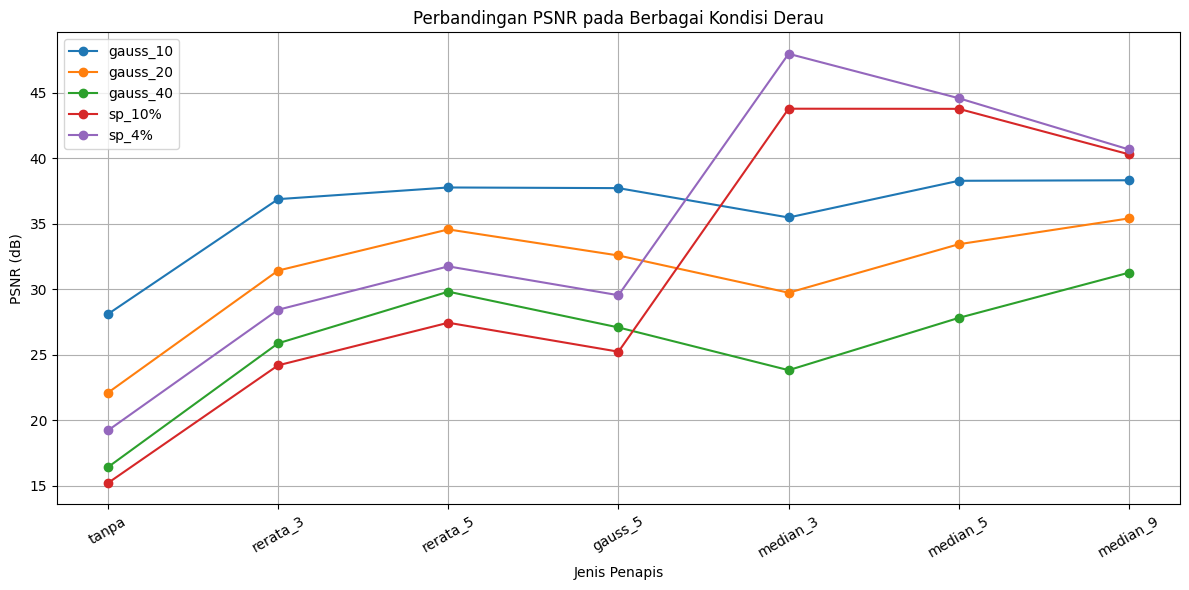

In [ ]:
plt.figure(figsize=(12, 6))

for nama_derau, data in tabel.groupby("derau"):
    plt.plot(
        data["penapis"],
        data["PSNR_dB"],
        marker="o",
        label=nama_derau
    )

plt.xlabel("Jenis Penapis")
plt.ylabel("PSNR (dB)")
plt.title("Perbandingan PSNR pada Berbagai Kondisi Derau")
plt.legend()
plt.grid()
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("../hasil/b4_grafik_psnr.png")
plt.show()

**Langkah 4.4 Apakah bercak kecil tetap terjaga**

Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil

In [ ]:
import pandas as pd

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())


label = pd.read_csv("../data/sintetis/label.csv")
baris = []

for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(
        baca(f"../data/sintetis/bersih/{nm}"),
        cv2.COLOR_BGR2GRAY)

    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)

    for k in [1, 3, 5, 9, 15]:
        out = g if k == 1 else cv2.medianBlur(g, k)

        baris.append([
            nm,
            k,
            selisih_rerata(out, md2, mb2),
            kontras_bercak(out, md2, mb2)])

hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
print(hasil_median.groupby("kernel")[["dI", "KB"]]
    .mean() .round(2))

           dI    KB
kernel             
1       31.64  4.98
3       31.98  5.11
5       30.97  5.03
9       24.68  4.63
15       7.36  1.90


**Langkah 4.5 Urutan meredam derau dan menajamkan**

Kode 4.4. Pengaruh urutan penajaman

In [ ]:
 def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)


noisy = derau["gauss_20"]
latar = md == 0

for nm, redam in {
    "Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median": lambda x: cv2.medianBlur(x, 5)
}.items():

    A = redam(unsharp(noisy))
    B = unsharp(redam(noisy))

    print(f"\n{nm}")
    print(f"Tajam -> Redam PSNR = {cv2.PSNR(bersih, A):.2f}")
    print(f"Sigma latar = {A[latar].std():.1f}")
    print(f"Redam -> Tajam PSNR = {cv2.PSNR(bersih, B):.2f}")
    print(f"Sigma latar = {B[latar].std():.1f}")


Gaussian
Tajam -> Redam PSNR = 30.37
Sigma latar = 7.9
Redam -> Tajam PSNR = 30.20
Sigma latar = 8.2

Median
Tajam -> Redam PSNR = 30.14
Sigma latar = 8.1
Redam -> Tajam PSNR = 31.12
Sigma latar = 7.2


**Langkah 4.6 Mengerjakan sendiri**

In [ ]:
daftar_citra = [
    f"teh_{i:03d}.png"
    for i in range(1, 57, 5)
]

print(daftar_citra)

baris_46 = []

for nama in daftar_citra:
    # Membaca citra yang memiliki derau sensor
    img_derau = cv2.cvtColor(
        baca(f"../data/sintetis/citra/{nama}"),
        cv2.COLOR_BGR2GRAY)

    # Membaca pasangan citra bersih
    img_bersih = cv2.cvtColor(
        baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)

    # PSNR sebelum penapisan
    psnr_sebelum = cv2.PSNR(img_bersih, img_derau)

    # Penapisan Median 3x3
    img_hasil = cv2.medianBlur(img_derau, 3)

    # PSNR sesudah penapisan
    psnr_sesudah = cv2.PSNR(img_bersih, img_hasil)

    baris_46.append([
        nama,
        psnr_sebelum,
        psnr_sesudah])

tabel_46 = pd.DataFrame(
    baris_46, columns=["nama_citra", "PSNR_sebelum", "PSNR_sesudah"]
    ).round(2)

print(tabel_46)
tabel_46.to_csv(
    "../hasil/b4_psnr_sensor_bawaan.csv",
    index=False
)

['teh_001.png', 'teh_006.png', 'teh_011.png', 'teh_016.png', 'teh_021.png', 'teh_026.png', 'teh_031.png', 'teh_036.png', 'teh_041.png', 'teh_046.png', 'teh_051.png', 'teh_056.png']
     nama_citra  PSNR_sebelum  PSNR_sesudah
0   teh_001.png         30.93         38.22
1   teh_006.png         29.97         37.32
2   teh_011.png         29.47         36.86
3   teh_016.png         31.71         38.87
4   teh_021.png         33.94         40.91
5   teh_026.png         29.59         36.93
6   teh_031.png         31.07         38.32
7   teh_036.png         32.66         39.69
8   teh_041.png         33.45         40.19
9   teh_046.png         29.66         36.93
10  teh_051.png         33.70         40.55
11  teh_056.png         29.03         36.35
